## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00429ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.29s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_simple 1.3 [b3b7fcb8|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_simple 1.3 [b3b7fcb8|fa6007dd3ce42e6d]'
00: ======================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_simple 01994b44/last.pt'... checkpoint version '1.2' does not match model version '1.3' - restarting experiment.
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_simple 01994b44/.
00: Launching 'AEC train_vol_vol_simple 1.3 [b3b7fcb8|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 512 for valuation.
01:   This model has 133441 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_simpl

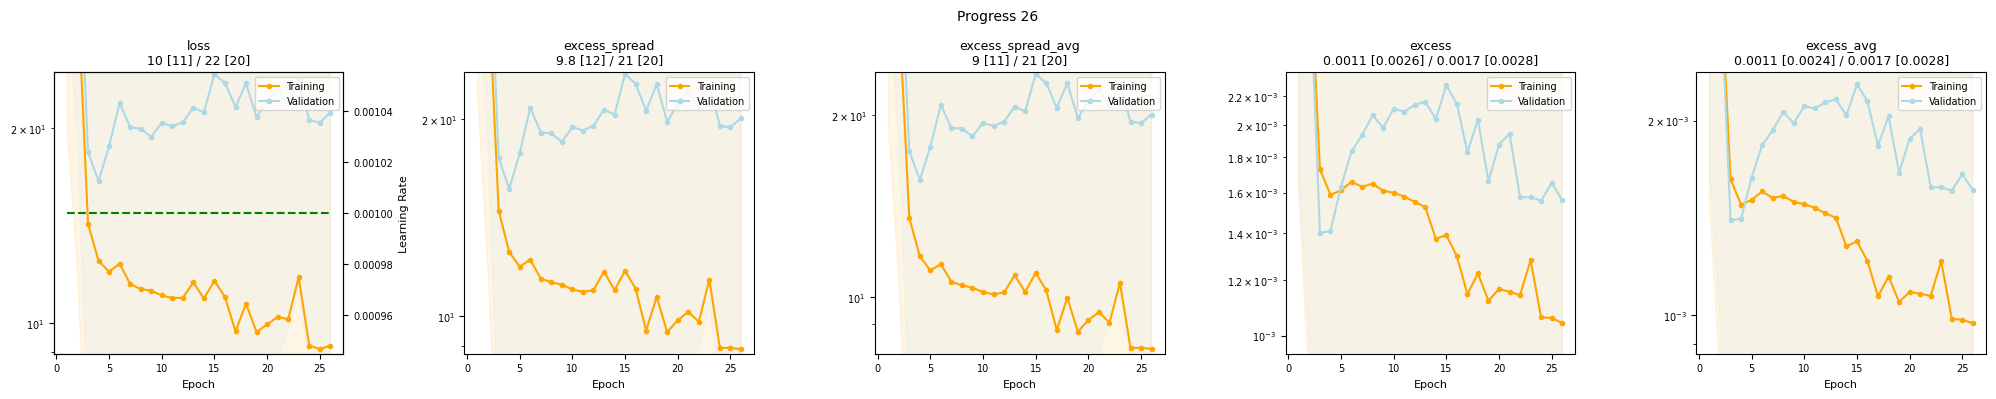

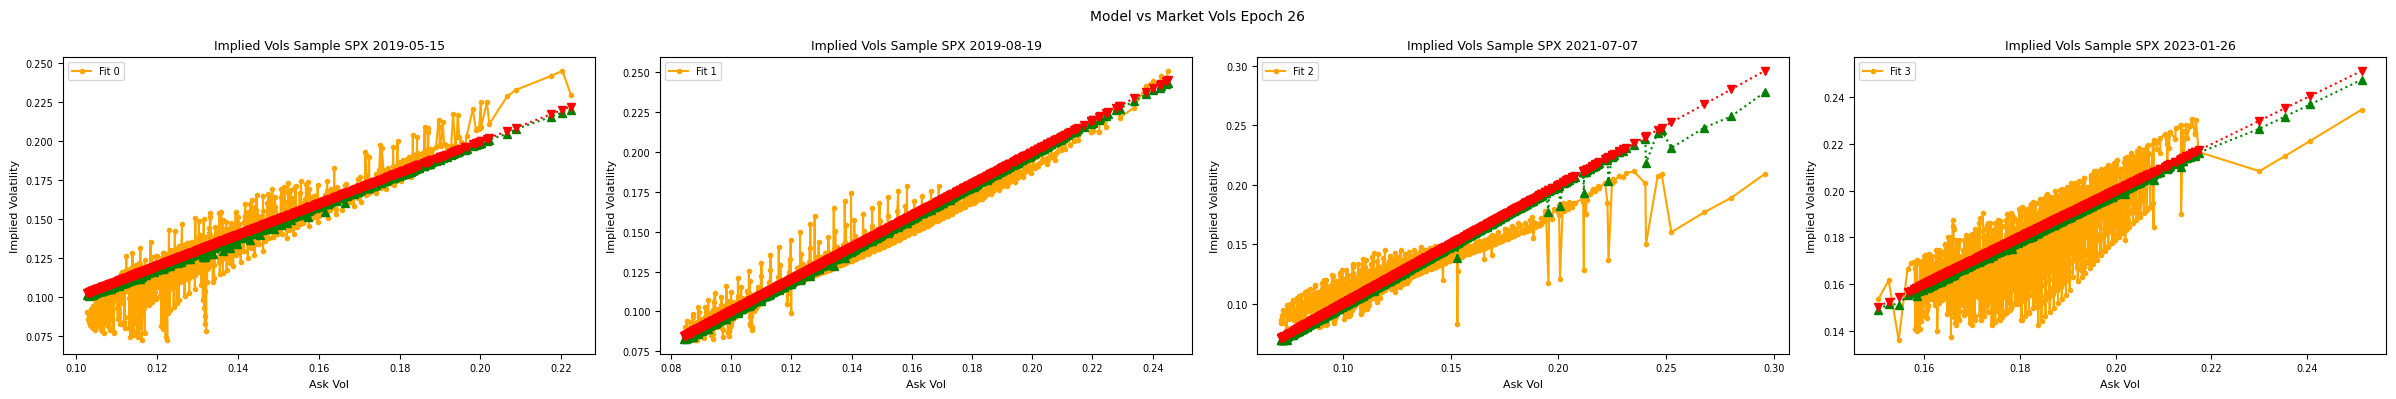

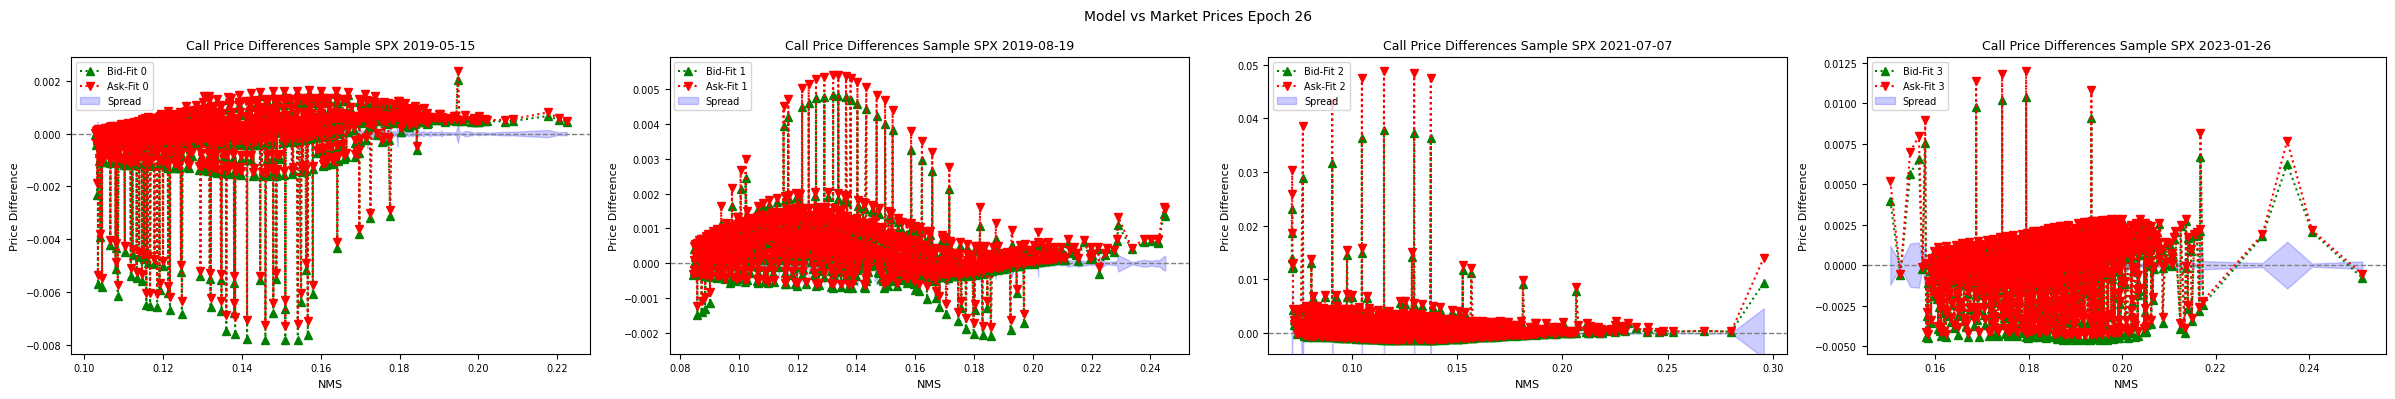

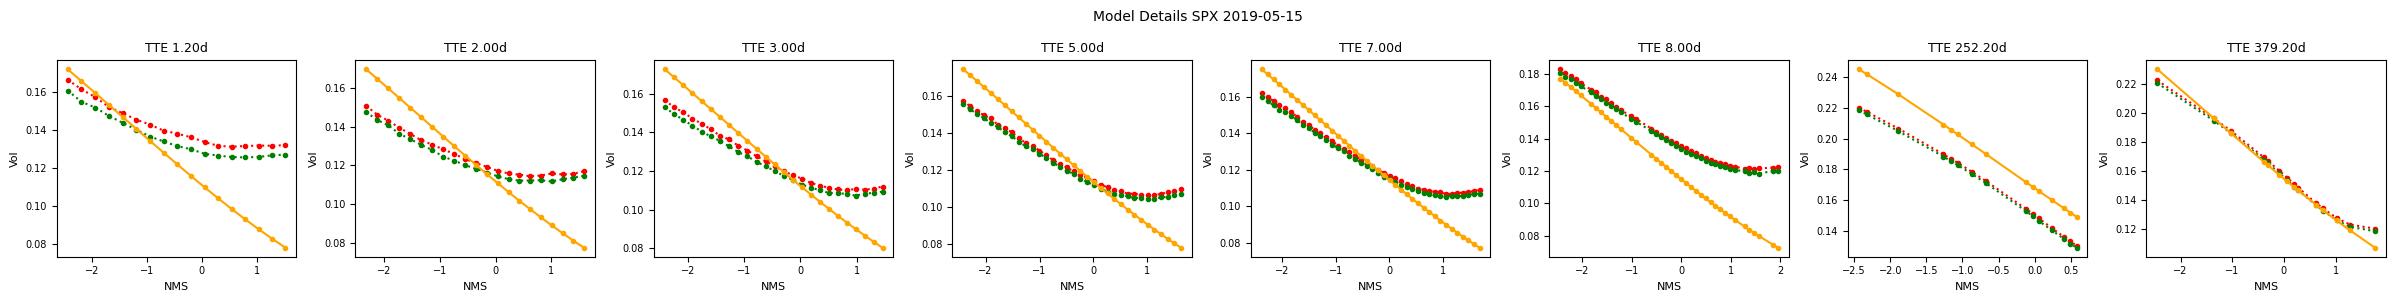

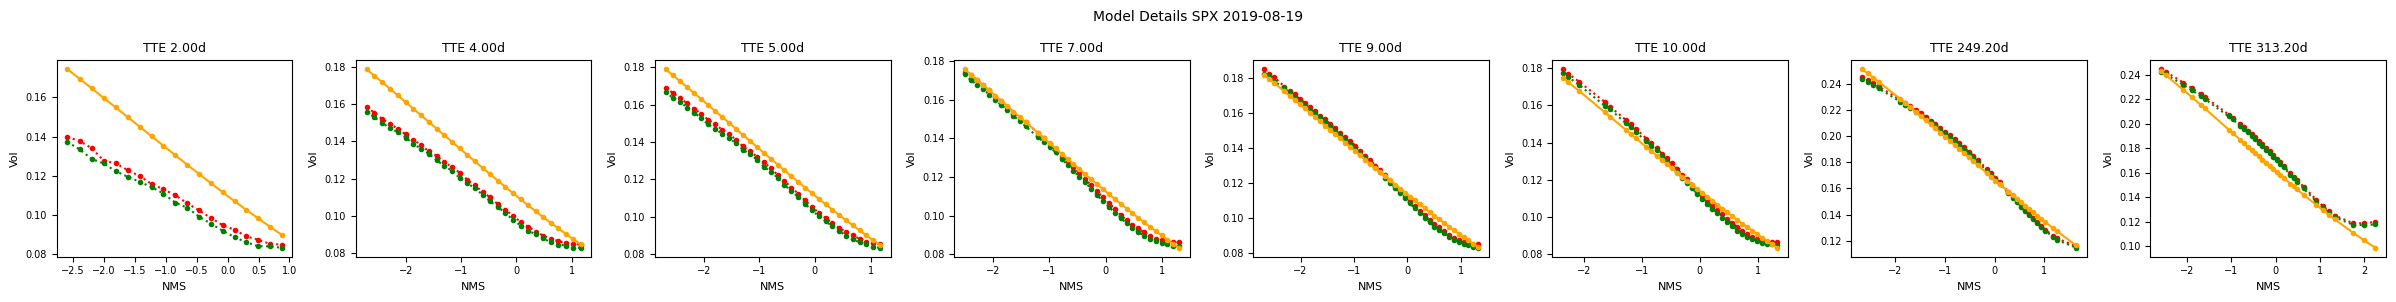

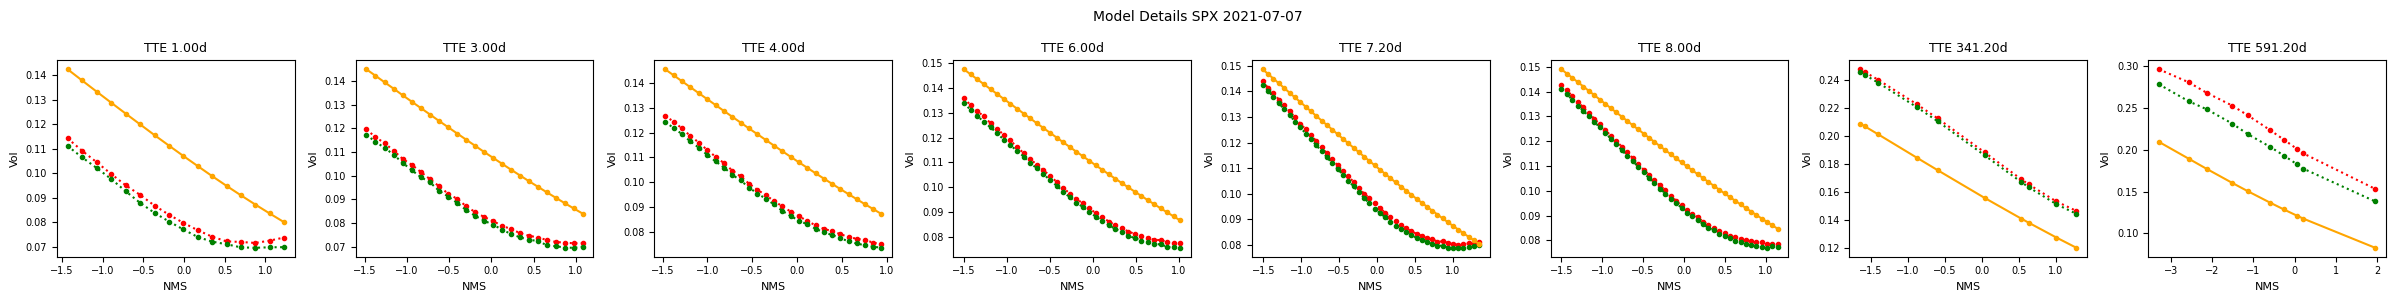

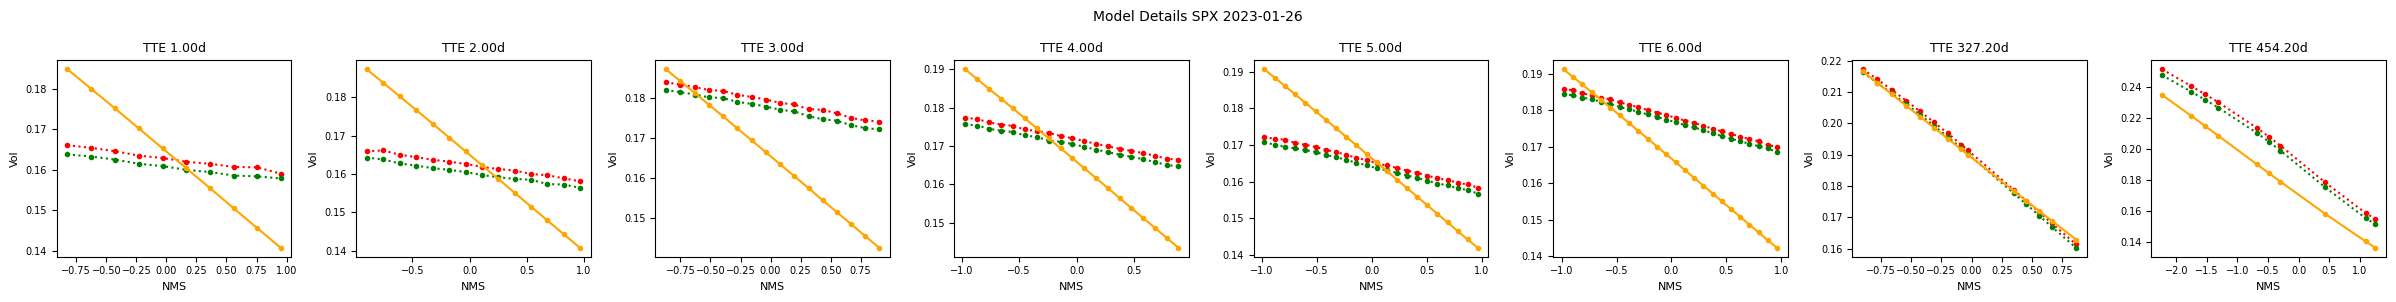

00: Training 'train_vol_vol_simple' epoch 2/1000 error avg trn 52.47; val 33.12/43.68 [47s 0.68s 0.68s]. LR: 1.00e-03, GN 27.1, excess_weighted: 0.00219/0.002037, excess_weighted_avg: 0.00255/0.002355, excess_spread: 32.43/42.22, excess_spread_avg: 30.56/42.22, excess: 0.003564/0.003376, excess_avg: 0.003488/0.003376. ETA: 14:31:25.
00: Training 'train_vol_vol_simple' epoch 3/1000 error avg trn 31.77; val 14.24/18.36 [1:10 0.68s 0.68s]. LR: 1.00e-03, GN 111.3, excess_weighted: 0.0009788/0.000842, excess_weighted_avg: 0.001226/0.0009827, excess_spread: 14.49/17.45, excess_spread_avg: 13.53/17.45, excess: 0.001728/0.001402, excess_avg: 0.001623/0.001402. ETA: 21:53:28.
00: Training 'train_vol_vol_simple' epoch 4/1000 error avg trn 14.22; val 12.48/16.58 [1:33 0.69s 0.68s]. LR: 1.00e-03, GN 20.73, excess_weighted: 0.0008459/0.0007542, excess_weighted_avg: 0.001083/0.0009143, excess_spread: 12.52/15.63, excess_spread_avg: 11.67/15.63, excess: 0.001588/0.001409, excess_avg: 0.001482/0.00140

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 128,
    fit_average = True,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 3,
            num_width = 64,
            activation = 'ReLU',
        ),
        fix_config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    ),
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.3", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, val_batch_size=512 )
